In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = iris.target_names[iris.target]

# Display the first 5 rows of the DataFrame
display(df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
# Display basic information about the DataFrame
df.info()

# Display descriptive statistics of the DataFrame
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


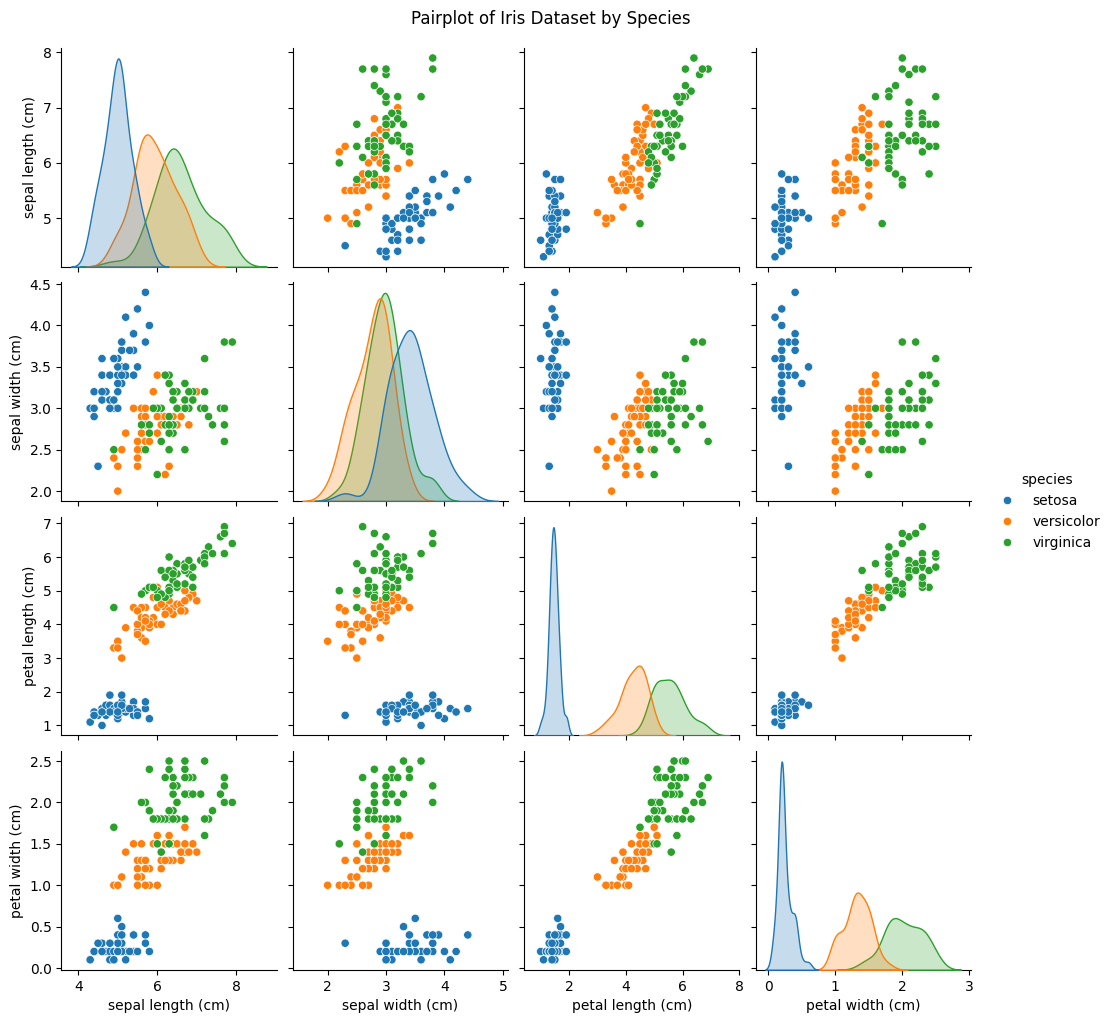

In [ ]:
# Create a pairplot to visualize relationships between features, colored by species
fig = sns.pairplot(df, hue='species')
plt.suptitle('Pairplot of Iris Dataset by Species', y=1.02) # Add a title to the pairplot
plt.show()

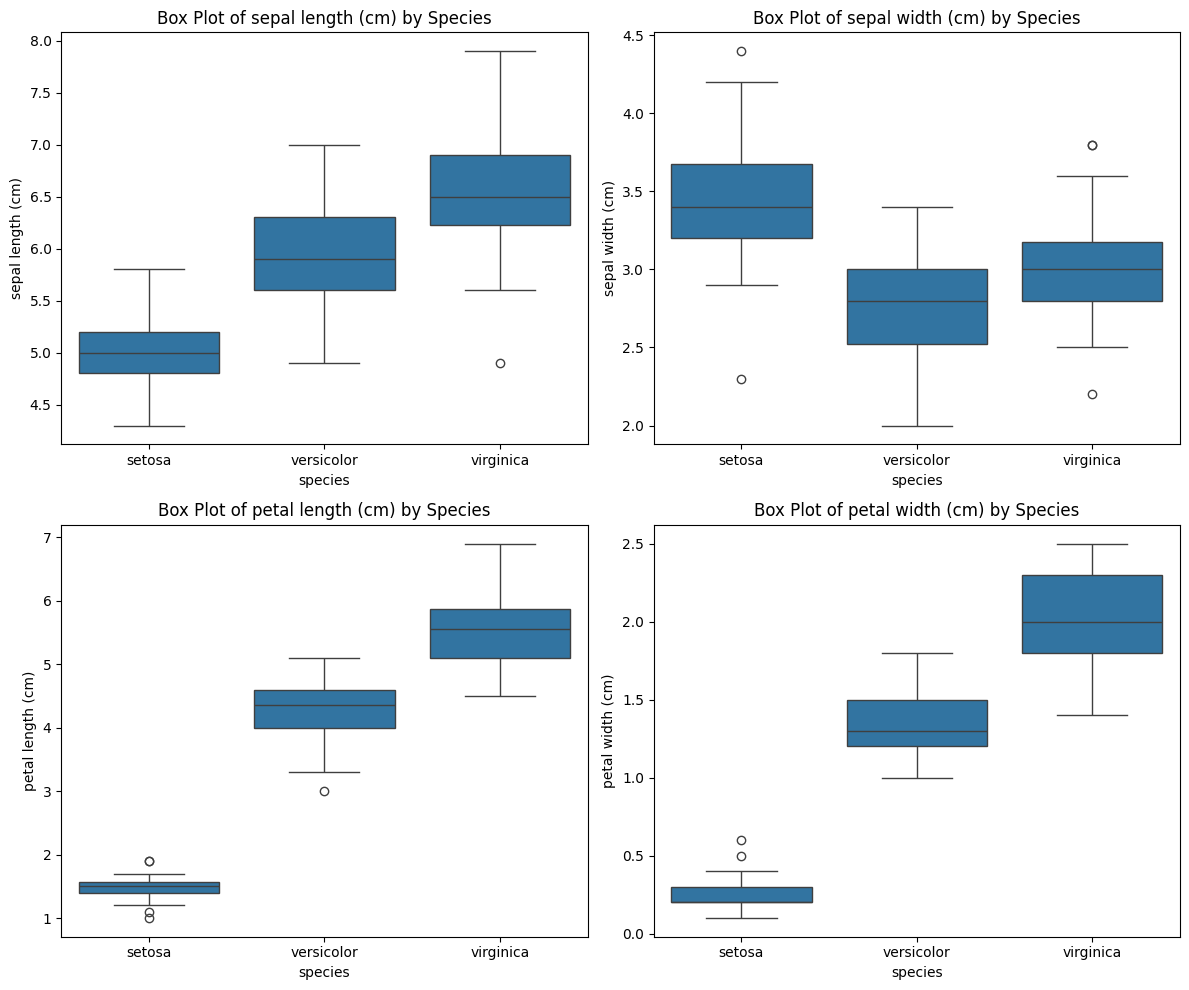

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

for i, feature in enumerate(features):
    row = i // 2
    col = i % 2
    sns.boxplot(x='species', y=feature, data=df, ax=axes[row, col])
    axes[row, col].set_title(f'Box Plot of {feature} by Species')

plt.tight_layout()
plt.show()

In [ ]:
# Select only the numeric columns for correlation calculation
numeric_df = df.select_dtypes(include=['float64'])

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Display the correlation matrix
display(correlation_matrix)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),1.000000,-0.117570,0.871754,0.817941
sepal width (cm),-0.117570,1.000000,-0.428440,-0.366126
petal length (cm),0.871754,-0.428440,1.000000,0.962865
petal width (cm),0.817941,-0.366126,0.962865,1.000000


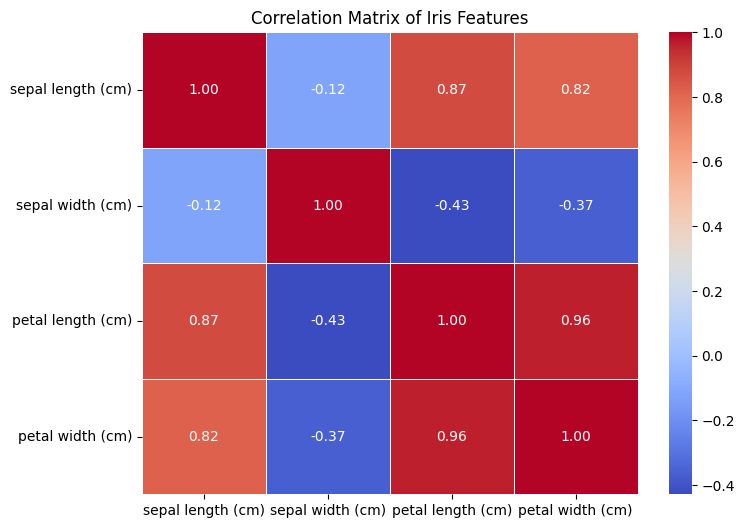

In [ ]:
# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Matrix of Iris Features')
plt.show()

## Train a Random Forest Classifier

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Separate features (X) and target (y)
X = df.drop('species', axis=1)
y = df['species']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Data split into training and testing sets.")
print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Data split into training and testing sets.
Training set size: 105 samples
Testing set size: 45 samples


In [ ]:
# Initialize the Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Random Forest Classifier trained successfully.")

Random Forest Classifier trained successfully.


In [ ]:
# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
print(report)

Accuracy: 1.00

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



## Cross-Validation for Model Performance

In [ ]:
from sklearn.model_selection import cross_val_score

# Perform k-fold cross-validation (e.g., 5-fold)
cv_scores = cross_val_score(model, X, y, cv=5)

print(f"Cross-validation scores: {cv_scores}")
print(f"Mean cross-validation score: {cv_scores.mean():.2f}")
print(f"Standard deviation of cross-validation scores: {cv_scores.std():.2f}")

Cross-validation scores: [0.96666667 0.96666667 0.93333333 0.96666667 1.        ]
Mean cross-validation score: 0.97
Standard deviation of cross-validation scores: 0.02


### Feature Importances

In [ ]:
importances = model.feature_importances_
feature_names = X.columns

# Create a DataFrame for better visualization
feature_importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})

# Sort the features by importance in descending order
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False)

# Display the feature importances
display(feature_importance_df)

,feature,importance
3,petal width (cm),0.433982
2,petal length (cm),0.417308
0,sepal length (cm),0.104105
1,sepal width (cm),0.044605


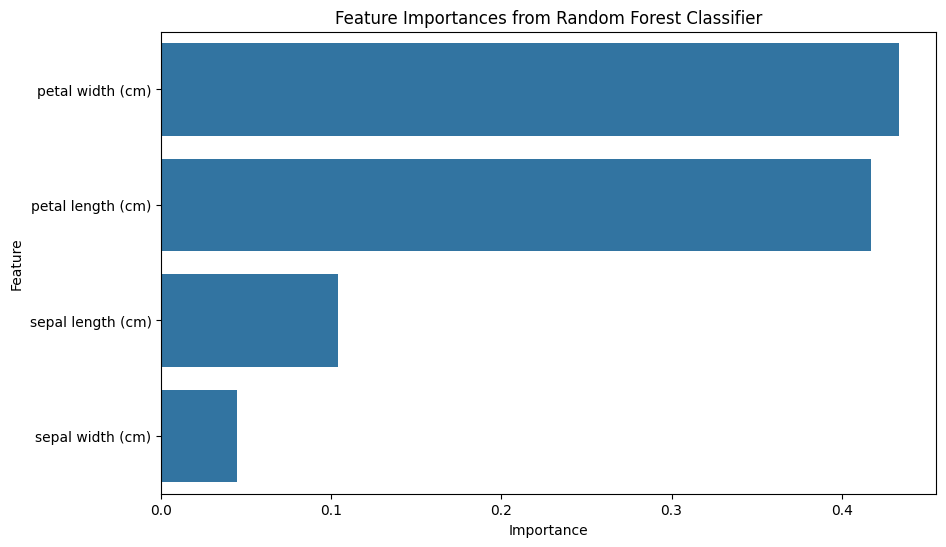

In [ ]:
# Visualize feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='importance', y='feature', data=feature_importance_df)
plt.title('Feature Importances from Random Forest Classifier')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

## Predict Species for New Samples

In [ ]:
new_samples = pd.DataFrame({
    'sepal length (cm)': [5.1, 6.5, 4.9],
    'sepal width (cm)': [3.5, 3.0, 3.2],
    'petal length (cm)': [1.4, 5.5, 1.3],
    'petal width (cm)': [0.2, 1.8, 0.2]
})

print("New samples to predict:")
display(new_samples)

New samples to predict:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,6.5,3.0,5.5,1.8
2,4.9,3.2,1.3,0.2


In [ ]:
predictions = model.predict(new_samples)

print("Predictions for the new samples:")
for i, sample in new_samples.iterrows():
    print(f"Sample {i+1}: {sample.tolist()} -> Predicted Species: {predictions[i]}")

Predictions for the new samples:
Sample 1: [5.1, 3.5, 1.4, 0.2] -> Predicted Species: setosa
Sample 2: [6.5, 3.0, 5.5, 1.8] -> Predicted Species: virginica
Sample 3: [4.9, 3.2, 1.3, 0.2] -> Predicted Species: setosa


### Predictions using Random Forest Model

In [ ]:
rf_predictions = model.predict(new_samples)

print("Random Forest Predictions for the new samples:")
for i, sample in new_samples.iterrows():
    print(f"Sample {i+1}: {sample.tolist()} -> Predicted Species: {rf_predictions[i]}")

### Predictions using SVM Model

In [ ]:
svm_predictions = svm_model.predict(new_samples)

print("SVM Predictions for the new samples:")
for i, sample in new_samples.iterrows():
    print(f"Sample {i+1}: {sample.tolist()} -> Predicted Species: {svm_predictions[i]}")

### Side-by-Side Comparison of Random Forest and SVM Classification Results

In [ ]:
print("--- Random Forest Model Classification Report ---")
print(report)
print(f"Random Forest Accuracy: {accuracy:.2f}")

print("\n--- SVM Model Classification Report ---")
print(report_svm)
print(f"SVM Accuracy: {accuracy_svm:.2f}")

print("\n--- Cross-Validation Score Comparison ---")
print(f"Random Forest Mean CV Score: {cv_scores.mean():.2f}")
print(f"SVM Mean CV Score: {cv_scores_svm.mean():.2f}")

if cv_scores.mean() > cv_scores_svm.mean():
    print("Conclusion: Random Forest performed slightly better on average with cross-validation.")
elif cv_scores_svm.mean() > cv_scores.mean():
    print("Conclusion: SVM performed slightly better on average with cross-validation.")
else:
    print("Conclusion: Both models performed similarly on average with cross-validation.")

--- Random Forest Model Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

Random Forest Accuracy: 1.00

--- SVM Model Classification Report ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

SVM Accuracy: 1.00

--- Cross-Validation Score Comparison ---
Random Forest Mean CV Score: 0.97
SVM Mean CV Score: 0.9

## Hyperparameter Tuning for SVM Model

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid for GridSearchCV
param_grid = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'kernel': ['linear', 'rbf', 'poly', 'sigmoid']  # Kernel type
}

# Initialize GridSearchCV
# svm_model is already defined as SVC(kernel='linear', random_state=42)
grid_search = GridSearchCV(svm_model, param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

print("GridSearchCV completed.")
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validation score: {grid_search.best_score_:.2f}")

GridSearchCV completed.
Best parameters: {'C': 1, 'kernel': 'poly'}
Best cross-validation score: 0.97


In [ ]:
# Get the best SVM model from GridSearchCV
best_svm_model = grid_search.best_estimator_

# Evaluate the best model on the test set
y_pred_best_svm = best_svm_model.predict(X_test)
accuracy_best_svm = accuracy_score(y_test, y_pred_best_svm)
report_best_svm = classification_report(y_test, y_pred_best_svm)

print(f"Tuned SVM Model Accuracy: {accuracy_best_svm:.2f}")
print("\nTuned SVM Model Classification Report:")
print(report_best_svm)

# Perform k-fold cross-validation for the best SVM model
cv_scores_best_svm = cross_val_score(best_svm_model, X, y, cv=5)

print(f"\nTuned SVM Cross-validation scores: {cv_scores_best_svm}")
print(f"Mean Tuned SVM cross-validation score: {cv_scores_best_svm.mean():.2f}")
print(f"Standard deviation of Tuned SVM cross-validation scores: {cv_scores_best_svm.std():.2f}")

Tuned SVM Model Accuracy: 0.98

Tuned SVM Model Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      0.92      0.96        13
   virginica       0.93      1.00      0.96        13

    accuracy                           0.98        45
   macro avg       0.98      0.97      0.97        45
weighted avg       0.98      0.98      0.98        45


Tuned SVM Cross-validation scores: [0.96666667 1.         0.96666667 0.96666667 1.        ]
Mean Tuned SVM cross-validation score: 0.98
Standard deviation of Tuned SVM cross-validation scores: 0.02


### Comparison with Untuned SVM Model

In [ ]:
print("--- Untuned SVM Model --- ")
print(f"Accuracy: {accuracy_svm:.2f}")
print(f"Mean CV Score: {cv_scores_svm.mean():.2f}")

print("\n--- Tuned SVM Model --- ")
print(f"Accuracy: {accuracy_best_svm:.2f}")
print(f"Mean CV Score: {cv_scores_best_svm.mean():.2f}")

if cv_scores_best_svm.mean() > cv_scores_svm.mean():
    print("\nConclusion: The tuned SVM model performed better on average with cross-validation.")
elif cv_scores_svm.mean() > cv_scores_best_svm.mean():
    print("\nConclusion: The untuned SVM model performed better on average with cross-validation.")
else:
    print("\nConclusion: Both untuned and tuned SVM models performed similarly on average with cross-validation.")

--- Untuned SVM Model --- 
Accuracy: 1.00
Mean CV Score: 0.98

--- Tuned SVM Model --- 
Accuracy: 0.98
Mean CV Score: 0.98

Conclusion: Both untuned and tuned SVM models performed similarly on average with cross-validation.


## Compare with Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC

# Initialize the Support Vector Machine Classifier
# Using 'linear' kernel for simplicity and to potentially interpret feature importance later if needed.
# For non-linear separation, 'rbf' (radial basis function) is a common choice.
svm_model = SVC(kernel='linear', random_state=42)

# Train the SVM model
svm_model.fit(X_train, y_train)

print("Support Vector Machine Classifier trained successfully.")

Support Vector Machine Classifier trained successfully.


In [ ]:
# Make predictions on the test set using SVM
y_pred_svm = svm_model.predict(X_test)

# Evaluate the SVM model
accuracy_svm = accuracy_score(y_test, y_pred_svm)
report_svm = classification_report(y_test, y_pred_svm)

print(f"SVM Accuracy: {accuracy_svm:.2f}")
print("\nSVM Classification Report:")
print(report_svm)

SVM Accuracy: 1.00

SVM Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



In [ ]:
# Perform k-fold cross-validation for the SVM model (e.g., 5-fold)
cv_scores_svm = cross_val_score(svm_model, X, y, cv=5)

print(f"SVM Cross-validation scores: {cv_scores_svm}")
print(f"Mean SVM cross-validation score: {cv_scores_svm.mean():.2f}")
print(f"Standard deviation of SVM cross-validation scores: {cv_scores_svm.std():.2f}")

# Compare with Random Forest results (assuming 'cv_scores' and 'accuracy' from RF are still in scope)
print("\n--- Comparison with Random Forest ---")
print(f"Random Forest Mean CV Score: {cv_scores.mean():.2f}")
print(f"SVM Mean CV Score: {cv_scores_svm.mean():.2f}")

if cv_scores.mean() > cv_scores_svm.mean():
    print("Random Forest performed slightly better on average with cross-validation.")
elif cv_scores_svm.mean() > cv_scores.mean():
    print("SVM performed slightly better on average with cross-validation.")
else:
    print("Both models performed similarly on average with cross-validation.")

SVM Cross-validation scores: [0.96666667 1.         0.96666667 0.96666667 1.        ]
Mean SVM cross-validation score: 0.98
Standard deviation of SVM cross-validation scores: 0.02

--- Comparison with Random Forest ---
Random Forest Mean CV Score: 0.97
SVM Mean CV Score: 0.98
SVM performed slightly better on average with cross-validation.


## Visualize SVM Decision Boundaries

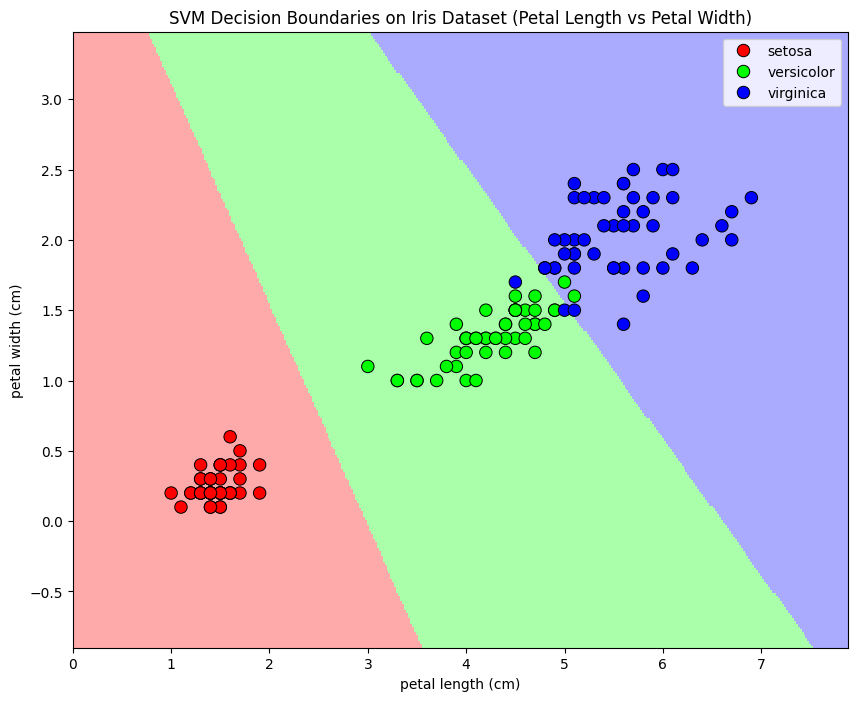

In [ ]:
from matplotlib.colors import ListedColormap
import numpy as np

def plot_decision_boundaries(X, y, model, feature_names, title):
    # Select the two most important features for plotting
    # Based on our feature importance analysis, petal length and petal width are most important.
    feature1_idx = X.columns.get_loc(feature_names[0])
    feature2_idx = X.columns.get_loc(feature_names[1])

    X_plot = X.iloc[:, [feature1_idx, feature2_idx]].values

    # Convert string labels to numerical for plotting
    unique_species = y.unique()
    species_to_int = {species: i for i, species in enumerate(unique_species)}
    y_plot = y.map(species_to_int).values

    # Define the mesh step size
    h = .02  # step size in the mesh

    # Create color maps
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ListedColormap(['#FF0000', '#00FF00', '#0000FF'])

    # Plot the decision boundary. For that, we will assign a color to each
    # point in the mesh [x_min, x_max]x[y_min, y_max].
    x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
    y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Create a dummy DataFrame for prediction to match the model's expected input structure
    # This is crucial because the model was trained on a DataFrame with specific column names
    X_grid = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feature_names)

    # Create a temporary model that only expects the two selected features
    # to predict on the meshgrid. We need to retrain a simple SVM with only these two features
    # or modify the original model's input expectation. For simplicity, we retrain a new one.
    temp_svm = SVC(kernel='linear', random_state=42)
    temp_svm.fit(X.iloc[:, [feature1_idx, feature2_idx]], y_plot)

    Z = temp_svm.predict(X_grid)
    Z = Z.reshape(xx.shape)

    # Put the result into a color plot
    plt.figure(figsize=(10, 8))
    plt.pcolormesh(xx, yy, Z, cmap=cmap_light)

    # Plot also the training points
    # Pass cmap_bold.colors to palette to avoid TypeError
    sns.scatterplot(x=X_plot[:, 0], y=X_plot[:, 1], hue=iris.target_names[y_plot],
                    palette=cmap_bold.colors, alpha=1.0, edgecolor="black", s=80)
    plt.xlabel(feature_names[0])
    plt.ylabel(feature_names[1])
    plt.title(title)
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.show()

# Get feature names from the original DataFrame X
selected_features = ['petal length (cm)', 'petal width (cm)']

# Plot decision boundaries for SVM model
plot_decision_boundaries(X, y, svm_model, selected_features, 'SVM Decision Boundaries on Iris Dataset (Petal Length vs Petal Width)')

In [ ]:
from sklearn.metrics import confusion_matrix

# Calculate the confusion matrix for the SVM model
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Get the unique class labels from the target variable
class_labels = iris.target_names

print("Confusion Matrix for SVM Model:")
display(pd.DataFrame(cm_svm, index=class_labels, columns=class_labels))

Confusion Matrix for SVM Model:


,setosa,versicolor,virginica
setosa,19,0,0
versicolor,0,13,0
virginica,0,0,13


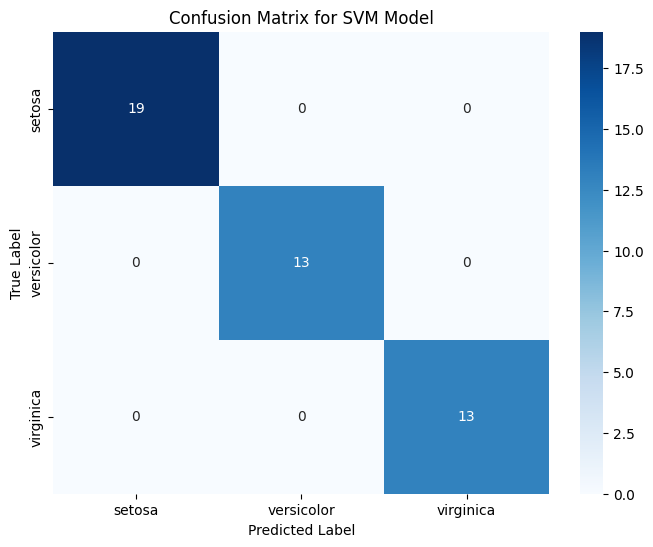

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix for SVM Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()